In [95]:
import pandas as pd
pd.set_option('display.max_columns', None)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timezone
import os
from pathlib import Path
import sys

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / "src"))

import database
import feature_pipeline

# Import data from the DB

In [96]:
df = feature_pipeline.get_features()

In [97]:
df

,year_month_t,log_10_UNRATE_t,log_10_INDPRO_t-1,log_10_JTSJOL_t-1,UNRATE_t,INDPRO_t-1,JTSJOL_t-1,UNRATE_t+1
0,2001-01,0.623249,1.965397,3.706547,4.2,92.3415,5088.0,4.2
1,2001-02,0.623249,1.963325,3.718834,4.2,91.9020,5234.0,4.3
2,2001-03,0.633468,1.960487,3.707315,4.3,91.3034,5097.0,4.4
3,2001-04,0.643453,1.959596,3.677789,4.4,91.1162,4762.0,4.3
4,2001-05,0.633468,1.958034,3.664172,4.3,90.7891,4615.0,4.5
...,...,...,...,...,...,...,...,...
303,2026-04,0.633468,2.007553,3.838030,4.3,101.7543,6887.0,4.3
304,2026-05,0.633468,2.010808,3.879956,4.3,102.5198,7585.0,4.2
305,2026-06,0.623249,2.010766,3.877199,4.2,102.5099,7537.0,4.1
306,2026-07,0.612784,2.011937,3.856245,4.1,102.7868,7182.0,4.1


In [98]:
df[df.isna().any(axis=1)]

,year_month_t,log_10_UNRATE_t,log_10_INDPRO_t-1,log_10_JTSJOL_t-1,UNRATE_t,INDPRO_t-1,JTSJOL_t-1,UNRATE_t+1
307,2026-08,0.612784,2.012812,3.861594,4.1,102.9939,7271.0,NaN


# Splitting data into feature sets

In [99]:
df.iloc[:, 1:].corr()

,log_10_UNRATE_t,log_10_INDPRO_t-1,log_10_JTSJOL_t-1,UNRATE_t,INDPRO_t-1,JTSJOL_t-1,UNRATE_t+1
log_10_UNRATE_t,1.000000,-0.627100,-0.742547,0.984889,-0.629432,-0.688645,0.936431
log_10_INDPRO_t-1,-0.627100,1.000000,0.702608,-0.614308,0.999715,0.611356,-0.593753
log_10_JTSJOL_t-1,-0.742547,0.702608,1.000000,-0.680238,0.704636,0.977581,-0.682087
UNRATE_t,0.984889,-0.614308,-0.680238,1.000000,-0.615229,-0.618496,0.944069
INDPRO_t-1,-0.629432,0.999715,0.704636,-0.615229,1.000000,0.613945,-0.594540
JTSJOL_t-1,-0.688645,0.611356,0.977581,-0.618496,0.613945,1.000000,-0.620240
UNRATE_t+1,0.936431,-0.593753,-0.682087,0.944069,-0.594540,-0.620240,1.000000


In [100]:
df.columns[[4,5]].to_list()

['UNRATE_t', 'INDPRO_t-1']

In [101]:
sets = {
'log10_set': df.columns[1:4].to_list(),
'levels_set': df.columns[4:-1].to_list(),
'mixed_set_1': df.columns[[3,4,5]].to_list(),
'mixed_set_2': df.columns[[2,4,6]].to_list()
}

target = 'UNRATE_t+1'

In [102]:
sets

{'log10_set': ['log_10_UNRATE_t', 'log_10_INDPRO_t-1', 'log_10_JTSJOL_t-1'],
 'levels_set': ['UNRATE_t', 'INDPRO_t-1', 'JTSJOL_t-1'],
 'mixed_set_1': ['log_10_JTSJOL_t-1', 'UNRATE_t', 'INDPRO_t-1'],
 'mixed_set_2': ['log_10_INDPRO_t-1', 'UNRATE_t', 'JTSJOL_t-1']}

In [103]:
df['year_month_t'].dtype

period[M]

In [104]:
backtest_last_origin = pd.Period("2020-01")
df[df['year_month_t'] <= (backtest_last_origin)]

,year_month_t,log_10_UNRATE_t,log_10_INDPRO_t-1,log_10_JTSJOL_t-1,UNRATE_t,INDPRO_t-1,JTSJOL_t-1,UNRATE_t+1
0,2001-01,0.623249,1.965397,3.706547,4.2,92.3415,5088.0,4.2
1,2001-02,0.623249,1.963325,3.718834,4.2,91.9020,5234.0,4.3
2,2001-03,0.633468,1.960487,3.707315,4.3,91.3034,5097.0,4.4
3,2001-04,0.643453,1.959596,3.677789,4.4,91.1162,4762.0,4.3
4,2001-05,0.633468,1.958034,3.664172,4.3,90.7891,4615.0,4.5
...,...,...,...,...,...,...,...,...
224,2019-09,0.544068,2.011312,3.856003,3.5,102.6390,7178.0,3.6
225,2019-10,0.556303,2.009840,3.852724,3.6,102.2917,7124.0,3.6
226,2019-11,0.556303,2.006158,3.862668,3.6,101.4281,7289.0,3.6
227,2019-12,0.556303,2.008333,3.838093,3.6,101.9372,6888.0,3.6


In [105]:
df['year_month_t'].max()

Period('2026-08', 'M')

# Model


**“MAE-Optimized Ridge Regression Model with RMSE-tuned hyperparameter ($\lambda$)”**

In [106]:
def ridge_naive_ensemble(feature_set = None,
                              df = df,
                              n_lambda_candidates = 50,
                              n_lambda_optimization_steps = 10,
                              lower_lambda = 1e-6,
                              upper_lambda = 1e4,
                              print_details = False,
                              forecast_mode = False,
                              backtest_last_origin = None):
    # zero-variance guard
    def zero_variance_guard(std_values):
        if np.any(np.isclose(std_values, 0)):
            raise ValueError("At least one feature has zero or near-zero standard deviation.")

    # if a backtesting end date is given, create a date-capped df
    if backtest_last_origin:
        if forecast_mode:
            raise Exception(f"In backtesting mode, no forecasts can be produced!")

        backtest_last_origin = pd.Period(backtest_last_origin, freq='M')

        if backtest_last_origin >= df['year_month_t'].max():
            raise Exception(f"Your last origin backtest date has to be before the most recent observation date ({df['year_month_t'].max()})!")
        
        df = df[df['year_month_t'] <= (backtest_last_origin)].copy()

        if len(df) < 10 * len(feature_set):
            raise Exception(f"For your back test end date are not enough observations available!\nPlease choose a end date beyond {(df['year_month_t'].min() + 10 * len(feature_set)) - 1}")

        print(f"BACKTEST MODE ENABLED")
        
    # split data into training, validation, test, and target
    target = "UNRATE_t+1"
    cols = ['year_month_t'] + feature_set + ['UNRATE_t', target]
    cols = list(dict.fromkeys(cols))

    df_tvt = df[cols].dropna().copy() # tvt -> training, validation, and testing

    set_len = len(df_tvt)
    
    # in chronological order form df_tvt: 60% training and optimizing lambda and MAE weighting,
    # 60% -> 80% validation, retrain up to 80%, test against last 20% (80% -> 100%)
    train_end = int(round(set_len*0.6))
    val_end = int(round(set_len*0.8))

    X_train = df_tvt[feature_set].iloc[:train_end].to_numpy()
    X_val = df_tvt[feature_set].iloc[train_end:val_end].to_numpy()
    X_train_full = df_tvt[feature_set].iloc[:val_end].to_numpy()
    X_test = df_tvt[feature_set].iloc[val_end:].to_numpy()

    y_train = df_tvt[target].iloc[:train_end].to_numpy()
    y_val = df_tvt[target].iloc[train_end:val_end].to_numpy()
    y_train_full = df_tvt[target].iloc[:val_end].to_numpy()
    y_test = df_tvt[target].iloc[val_end:].to_numpy()

    y_pred_naive_val = df_tvt['UNRATE_t'].iloc[train_end:val_end].to_numpy()
    y_pred_naive_test = df_tvt['UNRATE_t'].iloc[val_end:].to_numpy()

    # standardize via z-score X and centering y
    def standardizing_X_centering_y(X_train, X_input, y_train):
        X_train_mean = X_train.mean(axis=0)
        X_train_std = X_train.std(axis=0)
        zero_variance_guard(X_train_std)

        Z_train = (X_train - X_train_mean) / X_train_std
        Z_input = (X_input - X_train_mean) / X_train_std

        y_train_mean = y_train.mean()

        y_train_centered = y_train - y_train_mean

        return Z_train, Z_input, y_train_mean, y_train_centered

    # fit model
    def fit_model(Z_train, Z_input, y_train_centered, y_train_mean, penalty_param, mae_w, y_pred_naive):
        A = Z_train.T @ Z_train + penalty_param * np.eye(Z_train.shape[1])
        b = Z_train.T @ y_train_centered

        beta_coeffs = np.linalg.solve(A, b)

        y_pred_raw = y_train_mean + Z_input @ beta_coeffs
        y_pred = mae_w * y_pred_raw + (1 - mae_w) * y_pred_naive

        return y_pred

    # find best lambda (penalty_param)
    # actual lambda values, not exponents -> np.geomspace is logspace for non-exponent values
    best_penalty_param = None
    best_val_rmse = np.inf

    Z_train, Z_val, y_train_mean, y_train_centered = standardizing_X_centering_y(X_train=X_train, X_input=X_val, y_train=y_train)

    for step in range(n_lambda_optimization_steps):
        lambda_space = np.geomspace(
            lower_lambda,
            upper_lambda,
            n_lambda_candidates
        )

        rmse_values = np.empty(len(lambda_space))

        for i, penalty_param in enumerate(lambda_space):
            y_pred_val = fit_model(
                Z_train=Z_train,
                Z_input=Z_val,
                y_train_centered=y_train_centered,
                y_train_mean=y_train_mean,
                penalty_param=penalty_param,
                mae_w=1,
                y_pred_naive=1
            )

            rmse = np.sqrt(np.mean((y_val - y_pred_val) ** 2))
            rmse_values[i] = rmse
        

        # pos of best lambda in current search
        best_pos = np.argmin(rmse_values)

        step_best_penalty_param = lambda_space[best_pos]
        step_best_rmse = rmse_values[best_pos]

        # store best result found overall
        if step_best_rmse < best_val_rmse:
            best_val_rmse = step_best_rmse
            best_penalty_param = step_best_penalty_param

        # refine around the best lambda
        lower_pos = max(best_pos - 1, 0)
        upper_pos = min(best_pos + 1, len(lambda_space) - 1)

        lower_lambda = lambda_space[lower_pos]
        upper_lambda = lambda_space[upper_pos]

        if print_details:
            print(
                f"Step {step + 1}: "
                f"lambda={step_best_penalty_param:.6f}, "
                f"validation RMSE={step_best_rmse:.6f}"
            )

    # refit training model with best lambda (penalty_param)
    y_pred_val = fit_model(
        Z_train=Z_train,
        Z_input=Z_val,
        y_train_centered=y_train_centered,
        y_train_mean=y_train_mean,
        penalty_param=best_penalty_param,
        mae_w=1,
        y_pred_naive=1
    )

    # find a weighting for optimal MAE due to strong performance of naive model
    weight_candidates = np.linspace(0, 1, 101)

    best_mae_w = None
    best_weighted_val_mae = np.inf

    for weight in weight_candidates:

        y_pred_val_weighted = (weight * y_pred_val + (1 - weight) * y_pred_naive_val)

        weighted_val_mae = np.mean(np.abs(y_val - y_pred_val_weighted))

        if weighted_val_mae < best_weighted_val_mae:
            best_weighted_val_mae = weighted_val_mae
            best_mae_w = weight


    # refit model on 80%
    Z_train_full, Z_test, y_train_full_mean, y_train_full_centered = standardizing_X_centering_y(X_train_full, X_test, y_train_full)

    y_pred_test = fit_model(Z_train_full,
                            Z_test,
                            y_train_full_centered,
                            y_train_full_mean,
                            best_penalty_param,
                            best_mae_w,
                            y_pred_naive_test)
    
    # --- TEST METRICS ---

    # MAE in pp
    model_mae = np.mean(np.abs(y_test - y_pred_test))
    naive_mae = np.mean(np.abs(y_test - y_pred_naive_test))

    # RMSE in pp
    model_rmse = np.sqrt(np.mean((y_test - y_pred_test) ** 2))
    naive_rmse = np.sqrt(np.mean((y_test - y_pred_naive_test) ** 2))

    # MAPE in %
    model_mape = np.mean(np.abs((y_test - y_pred_test) / y_test)) * 100
    naive_mape = np.mean(np.abs((y_test - y_pred_naive_test) / y_test)) * 100

    # model over Naive improvement in %
    if naive_mae == 0:
        model_mae_improvement = np.nan
    else:
        model_mae_improvement = (1 - (model_mae / naive_mae)) * 100
    if naive_rmse == 0:
        model_rmse_improvement = np.nan
    else:
        model_rmse_improvement = (1 - (model_rmse / naive_rmse)) * 100

    df_test_metrics = pd.DataFrame([{
        "evaluation_training_start": df_tvt['year_month_t'].iloc[0],
        "evaluation_training_end": df_tvt['year_month_t'].iloc[val_end - 1],
        "test_start": df_tvt['year_month_t'].iloc[val_end],
        "test_end": df_tvt['year_month_t'].iloc[-1],
        "lambda": best_penalty_param,
        "mae_optimizing_weight": best_mae_w,
        "model_mae": model_mae,
        "naive_mae": naive_mae,
        "model_rmse": model_rmse,
        "naive_rmse": naive_rmse,
        "model_mae_improvement": model_mae_improvement,
        "model_rmse_improvement": model_rmse_improvement,
        "model_mape": model_mape,
        "naive_mape": naive_mape
    }])

    # --- TEST RESULTS ---

    df_test_results = pd.DataFrame({
        "forecast_origin_t": df_tvt['year_month_t'].iloc[val_end:].copy(),
        "forecast_target_t+1": df_tvt['year_month_t'].iloc[val_end:].copy() + 1,
        "UNRATE_t+1": y_test,
        "y_pred_model_t+1": y_pred_test,
        "y_pred_naive_t+1": y_pred_naive_test,
        "model_abs_error": np.abs(y_test - y_pred_test),
        "naive_abs_error": np.abs(y_test - y_pred_naive_test),
    }).reset_index(drop=True)

    # --- FORECAST MODE ---
    df_forecast = None

    if forecast_mode:
        # use all available data
        final_train_cols = ['year_month_t'] + feature_set + [target]
        final_train_cols = list(dict.fromkeys(final_train_cols))

        forecast_cols = (['year_month_t'] + feature_set + ['UNRATE_t'])
        forecast_cols = list(dict.fromkeys(forecast_cols))

        df_final_train = df[final_train_cols].dropna().copy()
        df_forecast_input = df[forecast_cols].dropna().tail(1).copy()

        X_final_train = df_final_train[feature_set].to_numpy()
        y_final_train = df_final_train[target].to_numpy()

        X_forecast_input = df_forecast_input[feature_set].to_numpy()
        y_forecast_naive = df_forecast_input['UNRATE_t'].to_numpy()

        Z_final_train, Z_forecast, y_final_train_mean, y_final_train_centered = standardizing_X_centering_y(X_final_train,
                                                                                                            X_forecast_input,
                                                                                                            y_final_train)

        y_forecast = fit_model(Z_final_train,
                               Z_forecast,
                               y_final_train_centered,
                               y_final_train_mean,
                               best_penalty_param,
                               best_mae_w,
                               y_forecast_naive)

        df_forecast = pd.DataFrame({
            "production_model_training_start": df_final_train['year_month_t'].iloc[0],
            "production_model_training_end": df_final_train['year_month_t'].iloc[-1],
            "forecast_origin_t": df_forecast_input['year_month_t'].to_numpy(),
            "forecast_target_t+1": (df_forecast_input['year_month_t'] + 1).to_numpy(),
            "lambda": best_penalty_param,
            "mae_optimizing_weight": best_mae_w,
            "UNRATE_forecast": y_forecast
        })

    return df_test_metrics, df_test_results, df_forecast  

## Backtesting Mode Test

In [107]:
df_test_metrics, df_test_results, df_forecast = ridge_naive_ensemble(feature_set = sets['mixed_set_1'],
                                                                 df = df,
                                                                 n_lambda_candidates = 50,
                                                                 n_lambda_optimization_steps = 10,
                                                                 lower_lambda = 1e-6,
                                                                 upper_lambda = 1e4,
                                                                 print_details = False,
                                                                 forecast_mode = False,
                                                                 backtest_last_origin = "2021-01")

BACKTEST MODE ENABLED


In [108]:
df_test_metrics

,evaluation_training_start,evaluation_training_end,test_start,test_end,lambda,mae_optimizing_weight,model_mae,naive_mae,model_rmse,naive_rmse,model_mae_improvement,model_rmse_improvement,model_mape,naive_mape
0,2001-01,2017-01,2017-02,2021-01,0.162636,1.0,0.443225,0.475,1.581525,1.59413,6.689507,0.790691,5.131255,5.377524


## Forecast Mode Test

In [109]:
df_test_metrics, df_test_results, df_forecast = ridge_naive_ensemble(feature_set = sets['mixed_set_1'],
                                                                          df = df,
                                                                 n_lambda_candidates = 50,
                                                                 n_lambda_optimization_steps = 10,
                                                                 lower_lambda = 1e-6,
                                                                 upper_lambda = 1e4,
                                                                 print_details = False,
                                                                 forecast_mode = True,
                                                                 backtest_last_origin = None)

In [110]:
df_test_metrics

,evaluation_training_start,evaluation_training_end,test_start,test_end,lambda,mae_optimizing_weight,model_mae,naive_mae,model_rmse,naive_rmse,model_mae_improvement,model_rmse_improvement,model_mape,naive_mape
0,2001-01,2021-06,2021-07,2026-07,4.487332,0.64,0.089833,0.103279,0.112936,0.138197,13.018753,18.2787,2.267573,2.567951


In [111]:
df_forecast

,production_model_training_start,production_model_training_end,forecast_origin_t,forecast_target_t+1,lambda,mae_optimizing_weight,UNRATE_forecast
0,2001-01,2026-07,2026-08,2026-09,4.487332,0.64,4.132956


# Feature Sets Testing

In [112]:
def feature_set_tester(keys=sets.keys(), plot_results=True):
    cols=["feature_set",
          "model_mae",
          "naive_mae",
          "model_rmse",
          "naive_rmse",
          "model_mae_improvement",
          "model_rmse_improvement",
          "model_mape",
          "naive_mape"]
    df_feature_set_comp = pd.DataFrame(columns=cols)
    
    for key in keys:
        df_test_metrics, df_test_results, df_forecast = ridge_naive_ensemble(feature_set = sets[key],
                                                                 df = df,
                                                                 n_lambda_candidates = 50,
                                                                 n_lambda_optimization_steps = 10,
                                                                 lower_lambda = 1e-6,
                                                                 upper_lambda = 1e4,
                                                                 print_details = False,
                                                                 forecast_mode = False,
                                                                 backtest_last_origin = None)

        new_row = pd.DataFrame([
            dict(zip(cols, [key,
                            df_test_metrics['model_mae'].item(),
                            df_test_metrics['naive_mae'].item(),
                            df_test_metrics['model_rmse'].item(),
                            df_test_metrics['naive_rmse'].item(),
                            df_test_metrics['model_mae_improvement'].item(),
                            df_test_metrics['model_rmse_improvement'].item(),
                            df_test_metrics['model_mape'].item(),
                            df_test_metrics['naive_mape'].item()]))
        ])
        df_feature_set_comp = pd.concat([df_feature_set_comp, new_row], ignore_index=True, axis=0)

        # --- ADD PLOTTING HERE ---
        if plot_results:
            fig, ax = plt.subplots(figsize=(10,5))
            ax.plot(df_test_results['forecast_target_t+1'].dt.strftime("%Y-%m"), df_test_results['UNRATE_t+1'], label=r"$y_{\text{test}}$")
            ax.plot(df_test_results['forecast_target_t+1'].dt.strftime("%Y-%m"), df_test_results['y_pred_model_t+1'], label=r"$\hat{y}_{\text{test}}$")
            ax.plot(df_test_results['forecast_target_t+1'].dt.strftime("%Y-%m"), df_test_results['y_pred_naive_t+1'], label=r"$\hat{y}_{\text{naive}}$")
            ax.tick_params("x", rotation=90, rotation_mode="xtick")
            ax.set_ylabel("UNRATE t")
            ax.set_title(f'UNRATE predict by feature set "{key}"')
            ax.legend()
            plt.tight_layout()
            plt.show()

    return df_feature_set_comp

In [113]:
feature_set_tester(plot_results=False)

,feature_set,model_mae,naive_mae,model_rmse,naive_rmse,model_mae_improvement,model_rmse_improvement,model_mape,naive_mape
0,log10_set,0.103279,0.103279,0.138197,0.138197,0.0,0.0,2.567951,2.567951
1,levels_set,0.094176,0.103279,0.117434,0.138197,8.813604,15.024113,2.37586,2.567951
2,mixed_set_1,0.089833,0.103279,0.112936,0.138197,13.018753,18.2787,2.267573,2.567951
3,mixed_set_2,0.094376,0.103279,0.117237,0.138197,8.619588,15.166319,2.386111,2.567951


# Experimenting

In [114]:
def ridge_regression(feature_set,
                     n_lambda_candidates = 50,
                     n_lambda_optimization_steps = 10,
                     lower_lambda = 1e-6,
                     upper_lambda = 1e4,
                     forecast_mode = False,
                     print_details = True):

    # zero-variance guard
    def zero_variance_guard(std_values):
        if np.any(np.isclose(std_values, 0)):
            raise ValueError("At least one feature has zero or near-zero standard deviation.")

    # split data into training (base for 60% val. and 80% full), validation, test, and forecasting data
    target = "UNRATE_t+1"
    
    cols = ['month_year'] + feature_set + ['UNRATE', target]
    cols = list(dict.fromkeys(cols))  # avoids duplicate UNRATE if already in feature_set
    df_train_test = df[cols].dropna().copy()

    set_len = len(df_train_test)

    train_end = int(round(set_len * 0.60))
    validation_end = int(round(set_len * 0.80))

    X_train = df_train_test[feature_set].iloc[:train_end].to_numpy()
    X_validation = df_train_test[feature_set].iloc[train_end:validation_end].to_numpy()
    X_train_full = df_train_test[feature_set].iloc[:validation_end].to_numpy()
    X_test = df_train_test[feature_set].iloc[validation_end:].to_numpy()

    y_train = df_train_test[target].iloc[:train_end].to_numpy()
    y_validation = df_train_test[target].iloc[train_end:validation_end].to_numpy()
    y_train_full = df_train_test[target].iloc[:validation_end].to_numpy()
    y_test = df_train_test[target].iloc[validation_end:].to_numpy()

    # standardize with z-score
    X_train_mean = X_train.mean(axis=0)
    X_train_std = X_train.std(axis=0)
    zero_variance_guard(X_train_std)
    y_train_mean = y_train.mean()

    Z_train = (X_train - X_train_mean) / X_train_std
    Z_validation = (X_validation - X_train_mean) / X_train_std

    y_train_centered = y_train - y_train_mean

    # lambda step-wise optimization parameters

    # actual lambda values, not exponents -> np.geomspace is logspace for non-exponent values

    best_lambda = None
    best_validation_rmse = np.inf

    for step in range(n_lambda_optimization_steps):

        lambda_space = np.geomspace(
            lower_lambda,
            upper_lambda,
            n_lambda_candidates
        )

        rmse_values = np.empty(len(lambda_space))

        for i, penalty_param in enumerate(lambda_space):

            A = Z_train.T @ Z_train + penalty_param * np.eye(Z_train.shape[1])
            b = Z_train.T @ y_train_centered

            beta_coeffs = np.linalg.solve(A, b)

            y_pred_validation = y_train_mean + Z_validation @ beta_coeffs

            rmse = np.sqrt(np.mean((y_validation - y_pred_validation) ** 2))

            rmse_values[i] = rmse

        # pos of best lambda in current search
        best_pos = np.argmin(rmse_values)

        step_best_lambda = lambda_space[best_pos]
        step_best_rmse = rmse_values[best_pos]

        # store best result found overall
        if step_best_rmse < best_validation_rmse:
            best_validation_rmse = step_best_rmse
            best_lambda = step_best_lambda

        # refine around the best lambda
        lower_pos = max(best_pos - 1, 0)
        upper_pos = min(best_pos + 1, len(lambda_space) - 1)

        lower_lambda = lambda_space[lower_pos]
        upper_lambda = lambda_space[upper_pos]

        if print_details == True:
            print(
                f"Step {step + 1}: "
                f"lambda={step_best_lambda:.8f}, "
                f"validation RMSE={step_best_rmse:.6f}"
            )

    A_best = Z_train.T @ Z_train + best_lambda * np.eye(Z_train.shape[1])
    b_best = Z_train.T @ y_train_centered

    beta_best = np.linalg.solve(A_best, b_best)

    y_pred_validation_best = y_train_mean + Z_validation @ beta_best

    # find an optimal weighting for a better MEA due to strong naive model
    y_pred_naive_validation = df_train_test["UNRATE"].iloc[train_end:validation_end].to_numpy()

    weight_candidates = np.linspace(0, 1, 101)

    best_weight = None
    best_combined_validation_mae = np.inf

    for weight in weight_candidates:
        y_pred_combined_validation = weight * y_pred_validation_best + (1 - weight) * y_pred_naive_validation
        combined_validation_mae = np.mean(np.abs(y_validation - y_pred_combined_validation))

        if combined_validation_mae < best_combined_validation_mae:
            best_combined_validation_mae = combined_validation_mae
            best_weight = weight

    # retrain using all target observations available before the test period
    X_train_full_mean = X_train_full.mean(axis=0)
    X_train_full_std = X_train_full.std(axis=0)
    zero_variance_guard(X_train_full_std)

    y_train_full_mean = y_train_full.mean()

    Z_train_full = (X_train_full - X_train_full_mean) / X_train_full_std
    Z_test = (X_test - X_train_full_mean) / X_train_full_std

    y_train_full_centered = y_train_full - y_train_full_mean

    A_final = Z_train_full.T @ Z_train_full + best_lambda * np.eye(Z_train_full.shape[1])
    b_final = Z_train_full.T @ y_train_full_centered

    beta_coeffs_final = np.linalg.solve(A_final,b_final)

    # evaluation on final 20% test set
    y_pred_test = y_train_full_mean + Z_test @ beta_coeffs_final
    y_pred_naive = df_train_test["UNRATE"].iloc[validation_end:].to_numpy()
    # in pp
    ridge_mae = np.mean(np.abs(y_test-y_pred_test))
    naive_mae = np.mean(np.abs(y_test-y_pred_naive))
    ridge_rmse = np.sqrt(np.mean((y_test - y_pred_test) ** 2))
    naive_rmse = np.sqrt(np.mean((y_test - y_pred_naive) ** 2))
    # in %
    mae_improvement = (1-(ridge_mae/naive_mae))*100
    rmse_improvement = (1-(ridge_rmse/naive_rmse))*100

    df_final_test_results = pd.DataFrame({
        "forecast_origin_t": df_train_test['month_year'].iloc[validation_end :].copy(),
        "forecast_target_t+1": df_train_test['month_year'].iloc[validation_end :].copy() + 1,
        "y_pred_test_t+1": y_pred_test,
        "y_pred_naive_t+1": y_pred_naive,
        "UNRATE_t+1": df_train_test[target].iloc[validation_end :].copy(),
        "ridge_abs_error": np.abs(df_train_test[target].iloc[validation_end :].to_numpy()-y_pred_test),
        "naive_abs_error": np.abs(df_train_test[target].iloc[validation_end :].to_numpy()-y_pred_naive),
    }).reset_index(drop=True)

    if print_details == True:
        print("Best lambda:", best_lambda)
        print(f"Validation RMSE: {best_validation_rmse} pp")
        print(f"Final test ridge regression model MAE: {ridge_mae} pp")
        print(f"Final test naive model MAE: {naive_mae} pp")
        print(f"Final test ridge regression model RMSE: {ridge_rmse} pp")
        print(f"Final test naive model RMSE: {naive_rmse} pp")
        print(f"Final test MAE improvement of ridge regression over the naive model: {mae_improvement}%")
        print(f"Final test RMSE improvement of ridge regression over the naive model: {rmse_improvement}%")
    

    # actual forecasting
    y_forecast = None
    if forecast_mode :
        # fits final production model on all observations
        df_final_train = df[['month_year'] + feature_set + [target]].dropna().copy()

        X_final = df_final_train[feature_set].to_numpy()
        y_final = df_final_train[target].to_numpy()

        X_final_mean = X_final.mean(axis=0)
        X_final_std = X_final.std(axis=0)
        zero_variance_guard(X_final_std)
        y_final_mean = y_final.mean()

        Z_final = (X_final - X_final_mean) / X_final_std

        y_final_centered = y_final - y_final_mean

        A = Z_final.T @ Z_final + best_lambda * np.eye(Z_final.shape[1])
        b = Z_final.T @ y_final_centered

        beta_final = np.linalg.solve(A, b)

        # Latest complete feature observation
        df_forecast = df[['month_year'] + feature_set].dropna().tail(1).copy()

        X_forecast = df_forecast[feature_set].to_numpy()
        Z_forecast = (X_forecast - X_final_mean) / X_final_std
        y_forecast = (y_final_mean + Z_forecast @ beta_final).item()

    return (best_lambda,
            best_validation_rmse,
            ridge_mae,
            naive_mae,
            ridge_rmse,
            naive_rmse,
            mae_improvement,
            rmse_improvement,
            df_final_test_results,
            y_forecast)

In [115]:
def ridge_regression(feature_set,
                     horizon,
                     n_lambda_candidates = 50,
                     n_lambda_optimization_steps = 10,
                     lower_lambda = 1e-6,
                     upper_lambda = 1e4,
                     forecast_mode = False):
    if horizon not in [1, 3, 6, 12]:
        raise ValueError(
            f"horizon must currently be 1, 3, 6, or 12 months. "
            f"Received {horizon}."
        )

    # split data into training (base for 60% val. and 80% full), validation, test, and forecasting data
    target_horizon = f"UNRATE_t+{horizon}"
    df_train_test = df[['month_year'] + feature_set + [target_horizon]].dropna().copy()

    set_len = len(df_train_test)

    train_end = int(round(set_len * 0.60))
    validation_end = int(round(set_len * 0.80))
    
    # prevent time-series leakage
    train_fit_end = train_end - horizon + 1
    train_full_fit_end = validation_end - horizon + 1

    if train_fit_end <= 0 or train_full_fit_end <= 0:
        raise ValueError(
            "Not enough observations for the selected forecast horizon."
        )

    X_train = df_train_test[feature_set].iloc[:train_fit_end].to_numpy()
    X_validation = df_train_test[feature_set].iloc[train_end:validation_end].to_numpy()
    X_train_full = df_train_test[feature_set].iloc[:train_full_fit_end].to_numpy()
    X_test = df_train_test[feature_set].iloc[validation_end:].to_numpy()

    y_train = df_train_test[target_horizon].iloc[:train_fit_end].to_numpy()
    y_validation = df_train_test[target_horizon].iloc[train_end:validation_end].to_numpy()
    y_train_full = df_train_test[target_horizon].iloc[:train_full_fit_end].to_numpy()
    y_test = df_train_test[target_horizon].iloc[validation_end:].to_numpy()

    # standardize with z-score
    X_train_mean = X_train.mean(axis=0)
    X_train_std = X_train.std(axis=0)
    y_train_mean = y_train.mean()

    Z_train = (X_train - X_train_mean) / X_train_std
    Z_validation = (X_validation - X_train_mean) / X_train_std

    y_train_centered = y_train - y_train_mean

    # lambda step-wise optimization parameters
    # n_lambda_candidates = 50
    # n_lambda_optimization_steps = 6

    # actual lambda values, not exponents -> np.geomspace is logspace for non-exponent values
    # lower_lambda = 1e-6
    # upper_lambda = 1e4

    best_lambda = None
    best_validation_rmse = np.inf

    for step in range(n_lambda_optimization_steps):

        lambda_space = np.geomspace(
            lower_lambda,
            upper_lambda,
            n_lambda_candidates
        )

        rmse_values = np.empty(len(lambda_space))

        for i, penalty_param in enumerate(lambda_space):

            A = Z_train.T @ Z_train + penalty_param * np.eye(Z_train.shape[1])
            b = Z_train.T @ y_train_centered

            beta_coeffs = np.linalg.solve(A, b)

            y_pred_validation = y_train_mean + Z_validation @ beta_coeffs

            rmse = np.sqrt(np.mean((y_validation - y_pred_validation) ** 2))

            rmse_values[i] = rmse

        # pos of best lambda in current search
        best_pos = np.argmin(rmse_values)

        step_best_lambda = lambda_space[best_pos]
        step_best_rmse = rmse_values[best_pos]

        # store best result found overall
        if step_best_rmse < best_validation_rmse:
            best_validation_rmse = step_best_rmse
            best_lambda = step_best_lambda

        # refine around the best lambda
        lower_pos = max(best_pos - 1, 0)
        upper_pos = min(best_pos + 1, len(lambda_space) - 1)

        lower_lambda = lambda_space[lower_pos]
        upper_lambda = lambda_space[upper_pos]

        print(
            f"Step {step + 1}: "
            f"lambda={step_best_lambda:.8f}, "
            f"validation RMSE={step_best_rmse:.6f}"
        )


    # retrain using all target observations available before the test period
    X_train_full_mean = X_train_full.mean(axis=0)
    X_train_full_std = X_train_full.std(axis=0)

    y_train_full_mean = y_train_full.mean()

    Z_train_full = (X_train_full - X_train_full_mean) / X_train_full_std
    Z_test = (X_test - X_train_full_mean) / X_train_full_std

    y_train_full_centered = y_train_full - y_train_full_mean

    A_final = Z_train_full.T @ Z_train_full + best_lambda * np.eye(Z_train_full.shape[1])
    b_final = Z_train_full.T @ y_train_full_centered

    beta_coeffs_final = np.linalg.solve(A_final,b_final)

    # evaluation on final 20% test set
    y_pred_test = y_train_full_mean + Z_test @ beta_coeffs_final
    test_rmse = np.sqrt(np.mean((y_test - y_pred_test) ** 2))

    df_final_test_results = pd.DataFrame({
        "forecast_origin": df_train_test['month_year'].iloc[validation_end :].copy(),
        "forecast_target": df_train_test['month_year'].iloc[validation_end :].copy() + horizon,
        "y_pred_test": y_pred_test,
        "UNRATE": df_train_test[target_horizon].iloc[validation_end :].copy()
    }).reset_index(drop=True)

    # df_80pct_test_results = df_train_test[['month_year'] + [target_horizon]].iloc[validation_end:].dropna().copy().rename(columns={target_horizon:'UNRATE'})
    # df_80pct_test_results['month_year'] = df_80pct_test_results['month_year'] + horizon
    # df_80pct_test_results['y_pred_test'] = y_pred_test

    print("Best lambda:", best_lambda)
    print("Validation RMSE:", best_validation_rmse)
    print("Final test RMSE:", test_rmse)

    # actual forecasting
    y_forecast = None
    if forecast_mode :
        # fits final production model on all observations
        df_final_train = df[['month_year'] + feature_set + [target_horizon]].dropna().copy()

        X_final = df_final_train[feature_set].to_numpy()
        y_final = df_final_train[target_horizon].to_numpy()

        X_final_mean = X_final.mean(axis=0)
        X_final_std = X_final.std(axis=0)
        y_final_mean = y_final.mean()

        Z_final = (X_final - X_final_mean) / X_final_std

        y_final_centered = y_final - y_final_mean

        A = Z_final.T @ Z_final + best_lambda * np.eye(Z_final.shape[1])
        b = Z_final.T @ y_final_centered

        beta_final = np.linalg.solve(A, b)

        # Latest complete feature observation
        df_forecast = df[['month_year'] + feature_set].dropna().tail(1).copy()

        X_forecast = (df_forecast[feature_set].to_numpy())
        Z_forecast = (X_forecast - X_final_mean) / X_final_std
        y_forecast = (y_final_mean + Z_forecast @ beta_final).item()

    return best_lambda, best_validation_rmse, test_rmse, df_final_test_results, y_forecast

In [116]:
def ridge_regression(feature_set,
                     horizon,
                     n_lambda_candidates = 50,
                     n_lambda_optimization_steps = 10,
                     lower_lambda = 1e-6,
                     upper_lambda = 1e4,
                     forecast_mode = False):
    if horizon in [1,3,6,12]:
        # split data into training (base for 60% val. and 80% full), validation, test, and forecasting data
        target_horizon = f"UNRATE_t+{horizon}"
        df_train_test = df[['month_year'] + feature_set + [target_horizon]].dropna().copy()

        set_len = len(df_train_test)

        train_end = int(round(set_len * 0.60))
        validation_end = int(round(set_len * 0.80))

        X_train = df_train_test[feature_set].iloc[:train_end].to_numpy()
        X_validation = df_train_test[feature_set].iloc[train_end:validation_end].to_numpy()
        X_train_full = df_train_test[feature_set].iloc[:validation_end].to_numpy()
        X_test = df_train_test[feature_set].iloc[validation_end:].to_numpy()

        y_train = df_train_test[target_horizon].iloc[:train_end].to_numpy()
        y_validation = df_train_test[target_horizon].iloc[train_end:validation_end].to_numpy()
        y_train_full = df_train_test[target_horizon].iloc[:validation_end].to_numpy()
        y_test = df_train_test[target_horizon].iloc[validation_end:].to_numpy()

        # standardize with z-score
        X_train_mean = X_train.mean(axis=0)
        X_train_std = X_train.std(axis=0)
        y_train_mean = y_train.mean()

        Z_train = (X_train - X_train_mean) / X_train_std
        Z_validation = (X_validation - X_train_mean) / X_train_std

        y_train_centered = y_train - y_train_mean

        # lambda step-wise optimization parameters
        # n_lambda_candidates = 50
        # n_lambda_optimization_steps = 6

        # actual lambda values, not exponents -> np.geomspace is logspace for non-exponent values
        # lower_lambda = 1e-6
        # upper_lambda = 1e4

        best_lambda = None
        best_validation_rmse = np.inf

        for step in range(n_lambda_optimization_steps):

            lambda_space = np.geomspace(
                lower_lambda,
                upper_lambda,
                n_lambda_candidates
            )

            rmse_values = np.empty(len(lambda_space))

            for i, penalty_param in enumerate(lambda_space):

                A = Z_train.T @ Z_train + penalty_param * np.eye(Z_train.shape[1])
                b = Z_train.T @ y_train_centered

                beta_coeffs = np.linalg.solve(A, b)

                y_pred_validation = y_train_mean + Z_validation @ beta_coeffs

                rmse = np.sqrt(np.mean((y_validation - y_pred_validation) ** 2))

                rmse_values[i] = rmse

            # pos of best lambda in current search
            best_pos = np.argmin(rmse_values)

            step_best_lambda = lambda_space[best_pos]
            step_best_rmse = rmse_values[best_pos]

            # store best result found overall
            if step_best_rmse < best_validation_rmse:
                best_validation_rmse = step_best_rmse
                best_lambda = step_best_lambda

            # refine around the best lambda
            lower_pos = max(best_pos - 1, 0)
            upper_pos = min(best_pos + 1, len(lambda_space) - 1)

            lower_lambda = lambda_space[lower_pos]
            upper_lambda = lambda_space[upper_pos]

            print(
                f"Step {step + 1}: "
                f"lambda={step_best_lambda:.8f}, "
                f"validation RMSE={step_best_rmse:.6f}"
            )


        # train on full 80% training set
        X_train_full_mean = X_train_full.mean(axis=0)
        X_train_full_std = X_train_full.std(axis=0)

        y_train_full_mean = y_train_full.mean()

        Z_train_full = (X_train_full - X_train_full_mean) / X_train_full_std
        Z_test = (X_test - X_train_full_mean) / X_train_full_std

        y_train_full_centered = y_train_full - y_train_full_mean

        A_final = Z_train_full.T @ Z_train_full + best_lambda * np.eye(Z_train_full.shape[1])
        b_final = Z_train_full.T @ y_train_full_centered

        beta_coeffs_final = np.linalg.solve(A_final,b_final)

        # evaluation on full 80% training set
        y_pred_test = y_train_full_mean + Z_test @ beta_coeffs_final
        test_rmse = np.sqrt(np.mean((y_test - y_pred_test) ** 2))

        df_80pct_test_results = df_train_test[['month_year'] + [target_horizon]].iloc[validation_end:].dropna().copy().rename(columns={target_horizon:'UNRATE'})
        df_80pct_test_results['month_year'] = df_80pct_test_results['month_year'] + horizon
        df_80pct_test_results['y_pred_test'] = y_pred_test

        print("Best lambda:", best_lambda)
        print("Validation RMSE:", best_validation_rmse)
        print("Final test RMSE:", test_rmse)

        # actual forecasting
        y_forecast = None
        if forecast_mode == True:
            # fits final production model on all observations
            df_final_train = df[['month_year'] + feature_set + [target_horizon]].dropna().copy()

            X_final = df_final_train[feature_set].to_numpy()
            y_final = df_final_train[target_horizon].to_numpy()

            X_final_mean = X_final.mean(axis=0)
            X_final_std = X_final.std(axis=0)
            y_final_mean = y_final.mean()

            Z_final = (X_final - X_final_mean) / X_final_std

            y_final_centered = y_final - y_final_mean

            A = Z_final.T @ Z_final + best_lambda * np.eye(Z_final.shape[1])
            b = Z_final.T @ y_final_centered

            beta_final = np.linalg.solve(A, b)

            # Latest complete feature observation
            df_forecast = df[['month_year'] + feature_set].dropna().tail(1).copy()

            X_forecast = (df_forecast[feature_set].to_numpy())
            Z_forecast = (X_forecast - X_final_mean) / X_final_std
            y_forecast = y_final_mean + Z_forecast @ beta_final

        return best_lambda, best_validation_rmse, test_rmse, df_80pct_test_results, y_forecast

    if not 1 <= horizon <= 12:
        raise ValueError(
            f"horizon must be between 1 and 12 months. "
            f"Received {horizon}."
        )

In [117]:
split_idx = int(len(df_train_test[feature_set])*0.8)
X_training = df_train_test[feature_set].iloc[:split_idx].to_numpy()
X_test = df_train_test[feature_set].iloc[split_idx:].to_numpy()

y_training = df_train_test[target_horizon].iloc[:split_idx].to_numpy()
y_test = df_train_test[target_horizon].iloc[split_idx:].to_numpy()

means_X_training = X_training.mean(axis=0)
stdevs_X_training = X_training.std(axis=0)

# mean_y_training is also \hat{beta}_0 
mean_y_training = y_training.mean()

# z-score standardized X features and target matrix
Z_training = (X_training - means_X_training)/stdevs_X_training
Z_test = (X_test - means_X_training)/stdevs_X_training
# X will be actual data to predict on
# Z = (X - means_X_training)/stdevs_X_training 

y_training_centered = y_training - mean_y_training

# lambda = penalty_param, @ shorthand for np.matmul(), arr.T shorthand for arr.transpose()
penalty_param = 1e-06

A = Z_training.T @ Z_training + penalty_param * np.identity(X_training.shape[1])
b = Z_training.T @ y_training_centered

beta_coeffs = np.linalg.solve(A,b)

y_pred = mean_y_training + Z_test @ beta_coeffs # Z_test to test and Z for actual data

NameError: name 'df_train_test' is not defined

In [ ]:
print(int(len(df_train_test[feature_set])))
print(int(len(df_train_test[feature_set])*0.6))
print(int(len(df_train_test[feature_set])*0.2))
print(int(len(df_train_test[feature_set])*0.2))

294
176
58
58


In [ ]:
round(len(df_train_test[feature_set])*0.6)

176

In [ ]:
np.array([len(df_train_test[feature_set])*0.6,len(df_train_test[feature_set])*0.2,len(df_train_test[feature_set])*0.2]).round().astype('int')

array([176,  59,  59])

In [ ]:
set_len = len(df_train_test[feature_set])
train_validate_test_idxs = np.array([set_len*0.6, set_len*0.8, set_len]).round().astype('int')

X_train_validate = df_train_test[feature_set].iloc[:train_validate_test_idxs[0]]
X_train_full = df_train_test[feature_set].iloc[: train_validate_test_idxs[1]]
X_test_validate = df_train_test[feature_set].iloc[train_validate_test_idxs[0]:train_validate_test_idxs[1]]
X_test_full = df_train_test[feature_set].iloc[train_validate_test_idxs[1]:]

y_train_validate = df_train_test[target_horizon].iloc[:train_validate_test_idxs[0]]
y_train_full = df_train_test[target_horizon].iloc[: train_validate_test_idxs[1]]
y_test_validate = df_train_test[target_horizon].iloc[train_validate_test_idxs[0]:train_validate_test_idxs[1]]
y_test_full = df_train_test[target_horizon].iloc[train_validate_test_idxs[1]:]

X_train_validate_means = X_train_validate.mean(axis=0)
X_train_full_means = X_train_full.mean(axis=0)
X_train_validate_stds = X_train_validate.std(axis=0)
X_train_full_stds = X_train_full.std(axis=0)

# aka \hat{\beta}_0
y_train_validate_mean = y_train_validate.mean()
y_train_full_mean = y_train_full.mean()

# z-score standardization
Z_train_validate = (X_train_validate - X_train_validate_means) / X_train_validate_stds
Z_train_full = (X_train_full - X_train_full_means) / X_train_full_stds
Z_test_validate = (X_test_validate - X_train_validate_means) / X_train_validate_stds
Z_test_full = (X_test_full - X_train_full_means) / X_train_full_stds

y_train_validate_centered = y_train_validate - y_train_validate_mean
y_train_full_centered = y_train_full - y_train_full_mean

# optimizing lambda (penalty_param)
min_max_lambda = np.array([1e-5, 1e5])
lambda_step_ranges = np.array([min_max_lambda])
lambda_space_subdivs = X_test_validate.shape[0]
optimization_steps = range(10)
rmse_collector = np.array([[np.inf, np.inf]])

for step in optimization_steps:
    lambda_space = np.geomspace(lambda_step_ranges[step][0], lambda_step_ranges[step][1], lambda_space_subdivs)
    temp_lambda = np.array([])
    temp_rmse = np.array([])

    for penalty_param in lambda_space:
        A = Z_train_validate.T @ Z_train_validate + penalty_param * np.eye(Z_train_validate.shape[1])
        b = Z_train_validate.T @ y_train_validate_centered
        beta_coeffs = np.linalg.solve(A,b)

        y_pred = y_train_validate_mean + Z_test_validate @ beta_coeffs

        rmse = np.sqrt(np.mean((y_test_validate - y_pred) ** 2))

        temp_lambda = np.append(temp_lambda, penalty_param)
        temp_rmse = np.append(temp_rmse, rmse)

    # adds two best lambda and rmse combos for next optimization step's lambda interval
    lambda_step_ranges = np.append(lambda_step_ranges, [temp_lambda[temp_rmse.argpartition(2)[:2]]], axis=0)
    rmse_collector = np.append(rmse_collector, [temp_rmse[temp_rmse.argpartition(2)[:2]]], axis=0)

rmse_collector


array([[       inf,        inf],
       [1.77927857, 1.7792786 ],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857],
       [1.77927857, 1.77927857]])

In [ ]:
lambda_step_ranges

array([[-5,  5]])

In [ ]:
arr = np.array([])

In [ ]:
arr = np.append(arr, 1.2)
arr

array([1. , 1.4, 1.8, 0.8, 0.2, 1.4, 1.2])

In [ ]:
lambda_step_ranges = np.append(lambda_step_ranges, [arr[arr.argpartition(2)[:2]]], axis=0)

In [ ]:
lambda_step_ranges[0]

array([-5.,  5.])

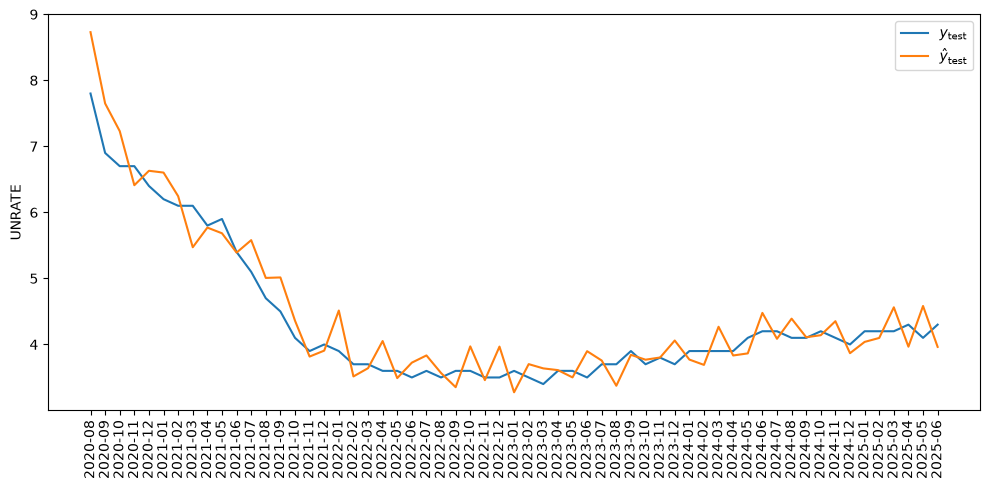

In [ ]:
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(df_train_test['month_year'].iloc[split_idx:].dt.strftime("%Y-%m"), df_train_test[target_horizon].iloc[split_idx:], label=r"$y_{\text{test}}$")
ax.plot(df_train_test['month_year'].iloc[split_idx:].dt.strftime("%Y-%m"), y_pred, label=r"$\hat{y}_{\text{test}}$")
ax.tick_params("x", rotation=90, rotation_mode="xtick")
ax.set_ylabel("UNRATE")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))
rmse

np.float64(0.3204423859870104)

In [ ]:
def feature_set_tester(keys=sets.keys(), plot_results=True):
    df_feature_set_comp = pd.DataFrame(columns=["feature_set",
                                                "ridge_mae",
                                                "naive_mae",
                                                "ridge_rmse",
                                                "naive_rmse",
                                                "combined_mae_improvement",
                                                "rcombined_mse_improvement"])
    for key in keys:
        (
        best_lambda,
        best_validation_rmse,
        best_weight,
        best_combined_validation_mae,
        ridge_mae,
        naive_mae,
        combined_mae,
        ridge_rmse,
        naive_rmse,
        combined_rmse,
        ridge_mae_improvement,
        combined_mae_improvement,
        ridge_rmse_improvement,
        combined_rmse_improvement,
        df_final_test_results,
        y_forecast_ridge,
        y_forecast_naive,
        y_forecast_combined) = ridge_regression(feature_set=sets[key], forecast_mode=False, print_details=False)

        new_row = pd.DataFrame([
            dict(zip(df_feature_set_comp.columns.to_list(), [key, combined_mae, naive_mae, combined_rmse, naive_rmse, combined_mae_improvement, combined_rmse_improvement]))
        ])
        df_feature_set_comp = pd.concat([df_feature_set_comp, new_row], ignore_index=True, axis=0)

        if plot_results == True:
            fig, ax = plt.subplots(figsize=(10,5))
            ax.plot(df_final_test_results['forecast_target_t+1'].dt.strftime("%Y-%m"), df_final_test_results['UNRATE_t+1'], label=r"$y_{\text{test}}$")
            ax.plot(df_final_test_results['forecast_target_t+1'].dt.strftime("%Y-%m"), df_final_test_results['y_pred_combined_t+1'], label=r"$\hat{y}_{\text{test}}$")
            ax.plot(df_final_test_results['forecast_target_t+1'].dt.strftime("%Y-%m"), df_final_test_results['y_pred_naive_t+1'], label=r"$\hat{y}_{\text{naive}}$")
            ax.tick_params("x", rotation=90, rotation_mode="xtick")
            ax.set_ylabel("UNRATE")
            ax.set_title(f'UNRATE predict by feature set "{key}"')
            ax.legend()
            plt.tight_layout()
            plt.show()    

    return df_feature_set_comp

